In [ ]:
!pip install pandas numpy pyarrow scikit-learn scipy

In [ ]:
import pandas as pd
import numpy as np
import os
import zipfile
import requests
from datetime import datetime, timezone

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
folders = ["bronze", "silver", "gold"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Data Lake folders created successfully!")

Data Lake folders created successfully!


In [ ]:
url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"

response = requests.get(url)
response.raise_for_status()

with open("book-crossings.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("book-crossings.zip", "r") as zip_ref:
    zip_ref.extractall("raw_data")

print("Dataset downloaded and extracted!")

Dataset downloaded and extracted!


In [ ]:
with open(
    "raw_data/BX-Books.csv",
    "r",
    encoding="latin-1"
) as f:
    for line_number, line in enumerate(f, start=1):
        if 6449 <= line_number <= 6454:
            print(f"Line {line_number}: {line}")

Line 6449: "0297828991";"Mr Foreigner";"Matthew Kneale";"2003";"Trafalgar Square";"http://images.amazon.com/images/P/0297828991.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0297828991.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0297828991.01.LZZZZZZZ.jpg"

Line 6450: "0061013722";"The Clairvoyant";"Marian Thurm";"1999";"HarperTorch";"http://images.amazon.com/images/P/0061013722.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0061013722.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0061013722.01.LZZZZZZZ.jpg"

Line 6451: "0451163540";"Triple";"Ken Follett";"1991";"Signet Book";"http://images.amazon.com/images/P/0451163540.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0451163540.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0451163540.01.LZZZZZZZ.jpg"

Line 6452: "0735201994";"Peterman Rides Again: Adventures Continue with the Real \"J. Peterman\" Through Life &amp; the Catalog Business";"John Peterman";"2000";"Prentice Hall Art";"http://images.amazon

In [ ]:
books = pd.read_csv(
    "raw_data/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    engine="python",
    escapechar="\\"
)

print("Books dataset loaded successfully!")
print("Books shape:", books.shape)

display(books.head())

Books dataset loaded successfully!
Books shape: (271379, 8)


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [ ]:
ratings = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1"
)

print("Ratings dataset loaded successfully!")

Ratings dataset loaded successfully!


In [ ]:
import pandas as pd
import csv

# Load Users
users = pd.read_csv(
    "raw_data/BX-Users.csv",
    sep=";",
    encoding="latin-1"
)

# Load Books (handle malformed rows)
books = pd.read_csv(
    "raw_data/BX-Books.csv",
    sep=";",
    encoding="latin-1",
    on_bad_lines="warn",
    engine="python"
)

# Load Ratings
ratings = pd.read_csv(
    "raw_data/BX-Book-Ratings.csv",
    sep=";",
    encoding="latin-1"
)

print("All three datasets loaded successfully!")

/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 815: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 1679: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 2531: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 2640: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 3236: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 3256: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 4906: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: ParserWarning: Skipping line 6452: ';' expected after '"'

  books = pd.read_csv(
/tmp/ipykernel_1973/2635739898.py:12: Par

All three datasets loaded successfully!


In [ ]:
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

Users: (278858, 3)
Books: (270491, 8)
Ratings: (1149780, 3)


In [ ]:
ingestion_time = datetime.now(timezone.utc)

users["ingestion_timestamp"] = ingestion_time
books["ingestion_timestamp"] = ingestion_time
ratings["ingestion_timestamp"] = ingestion_time

users.to_parquet("bronze/users.parquet", index=False)
books.to_parquet("bronze/books.parquet", index=False)
ratings.to_parquet("bronze/ratings.parquet", index=False)

print("Bronze layer created successfully!")
print(os.listdir("bronze"))

Bronze layer created successfully!
['users.parquet', 'ratings.parquet', 'books.parquet']


In [ ]:
users_bronze = pd.read_parquet("bronze/users.parquet")
books_bronze = pd.read_parquet("bronze/books.parquet")
ratings_bronze = pd.read_parquet("bronze/ratings.parquet")

print("Bronze data loaded successfully!")

Bronze data loaded successfully!


In [ ]:
datasets = {
    "Users": users_bronze,
    "Books": books_bronze,
    "Ratings": ratings_bronze
}

for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("\nShape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())


Users

Shape: (278858, 4)

Data Types:
User-ID                              int64
Location                            object
Age                                float64
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
User-ID                     0
Location                    0
Age                    110762
ingestion_timestamp         0
dtype: int64

Books

Shape: (270491, 9)

Data Types:
ISBN                                object
Book-Title                          object
Book-Author                         object
Year-Of-Publication                  int64
Publisher                           object
Image-URL-S                         object
Image-URL-M                         object
Image-URL-L                         object
ingestion_timestamp    datetime64[us, UTC]
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M     

In [ ]:
print("Rating Distribution:")
print(ratings_bronze["Book-Rating"].value_counts().sort_index())

Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


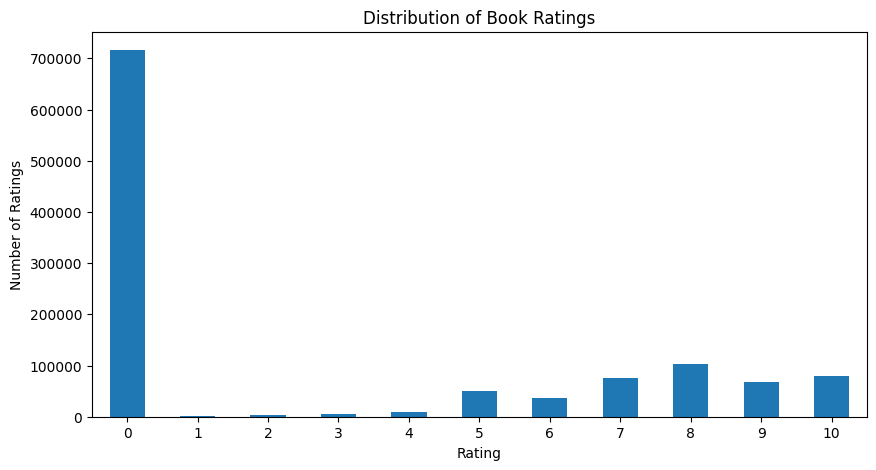

In [ ]:
import matplotlib.pyplot as plt

rating_counts = ratings_bronze["Book-Rating"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
rating_counts.plot(kind="bar")

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.show()

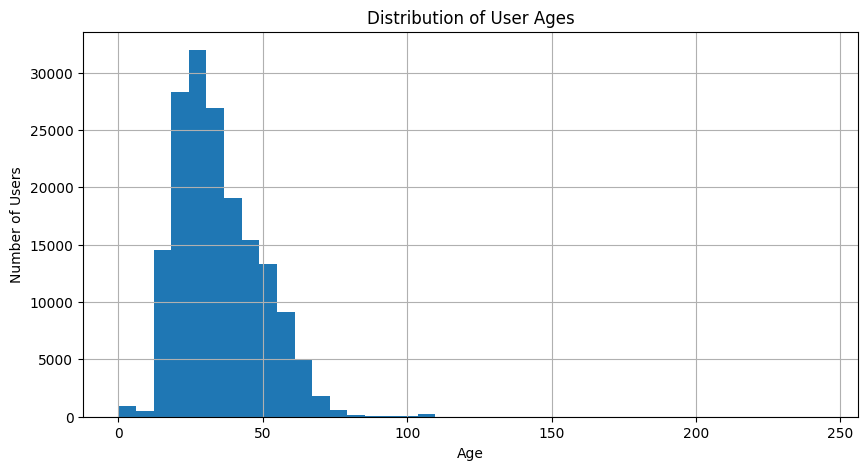

In [ ]:
plt.figure(figsize=(10, 5))

users_bronze["Age"].dropna().hist(bins=40)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")

plt.show()

In [ ]:
print("Minimum age:", users_bronze["Age"].min())
print("Maximum age:", users_bronze["Age"].max())

print("\nUsers below 5:")
print((users_bronze["Age"] < 5).sum())

print("\nUsers above 100:")
print((users_bronze["Age"] > 100).sum())

Minimum age: 0.0
Maximum age: 244.0

Users below 5:
882

Users above 100:
366


In [ ]:
print("Minimum publication year:",
      books_bronze["Year-Of-Publication"].min())

print("Maximum publication year:",
      books_bronze["Year-Of-Publication"].max())

print("\nMost common publication years:")
print(books_bronze["Year-Of-Publication"].value_counts().head(15))

Minimum publication year: 0
Maximum publication year: 2050

Most common publication years:
Year-Of-Publication
2002    17589
1999    17375
2001    17312
2000    17187
1998    15715
1997    14816
2003    14326
1996    13978
1995    13487
1994    11752
1993    10561
1992     9866
1991     9362
1990     8628
1989     7911
Name: count, dtype: int64


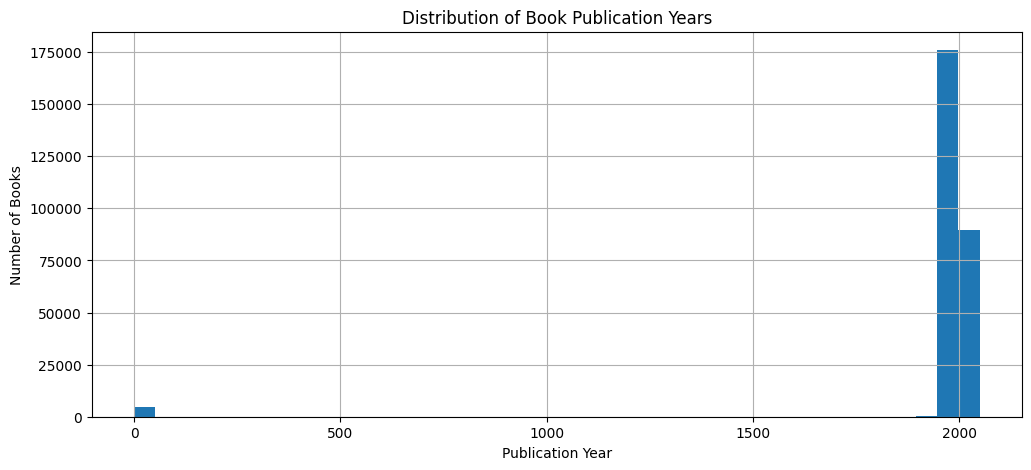

In [ ]:
plt.figure(figsize=(12, 5))

books_bronze["Year-Of-Publication"].hist(bins=40)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")

plt.show()

In [ ]:
ratings_per_user = ratings_bronze.groupby(
    "User-ID"
).size()

ratings_per_book = ratings_bronze.groupby(
    "ISBN"
).size()

print("Ratings per User:")
print(ratings_per_user.describe())

print("\nRatings per Book:")
print(ratings_per_book.describe())

Ratings per User:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

Ratings per Book:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64


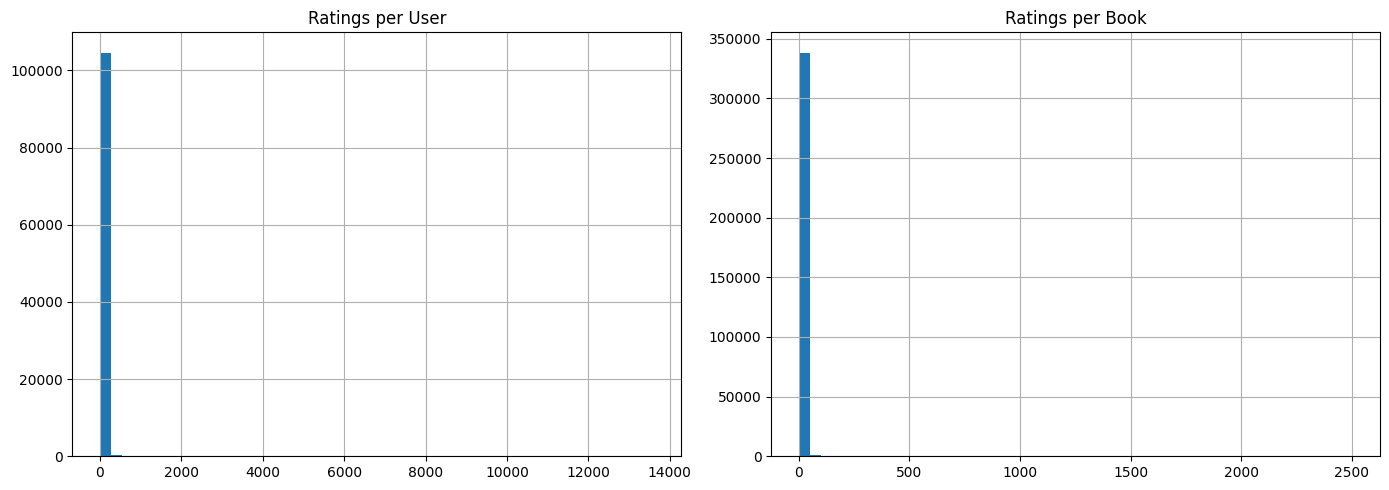

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ratings_per_user.hist(bins=50, ax=axes[0])
axes[0].set_title("Ratings per User")

ratings_per_book.hist(bins=50, ax=axes[1])
axes[1].set_title("Ratings per Book")

plt.tight_layout()
plt.show()

In [ ]:
total_users = ratings_bronze["User-ID"].nunique()
total_books = ratings_bronze["ISBN"].nunique()
total_ratings = len(ratings_bronze)

total_possible_pairs = total_users * total_books

sparsity = (
    1 - total_ratings / total_possible_pairs
) * 100

print("Unique Users:", total_users)
print("Unique Books:", total_books)
print("Actual Ratings:", total_ratings)
print("Possible User-Book Pairs:", total_possible_pairs)

print(f"Matrix Sparsity: {sparsity:.4f}%")

Unique Users: 105283
Unique Books: 340556
Actual Ratings: 1149780
Possible User-Book Pairs: 35854757348
Matrix Sparsity: 99.9968%


Bronze Layer – EDA Findings and Observations
1. Dataset Structure and Data Quality

The Bronze layer contains three raw datasets: Users, Books, and Ratings. The datasets have different column structures and contain missing values, inconsistent data types, and duplicate records. These issues need to be handled during the Silver transformation.

2. Rating Distribution

The ratings dataset contains both explicit ratings and zero values. Zero ratings represent implicit feedback rather than explicit user ratings. Therefore, zero ratings are removed, and only ratings between 1 and 10 are retained.

3. User Age Distribution

The user dataset contains invalid ages, including values below 5 and above 100. These values are treated as missing and replaced with the median age to maintain data consistency.

4. Book Publication Years

The publication year column contains missing, zero, and future-year values. These invalid values are converted to missing values during Silver transformation.

5. Ratings per User and Book

The ratings are unevenly distributed across users and books. Many users and books have very few ratings, which can reduce recommendation quality. A minimum threshold of 10 ratings is applied to retain sufficiently active users and books.

6. User-Book Matrix Sparsity

The user-book interaction matrix is approximately 99.9968% sparse, meaning most users have not rated most books. Therefore, a sparse matrix representation and item-based collaborative filtering are suitable for this recommendation system.

Conclusion: The EDA helped identify data quality issues and informed the cleaning and filtering decisions implemented in the Silver layer.

In [ ]:
# Load Bronze data
users_silver = pd.read_parquet("bronze/users.parquet").copy()
books_silver = pd.read_parquet("bronze/books.parquet").copy()
ratings_silver = pd.read_parquet("bronze/ratings.parquet").copy()

print("Bronze data copied for Silver transformation!")

print("Users:", users_silver.shape)
print("Books:", books_silver.shape)
print("Ratings:", ratings_silver.shape)

Bronze data copied for Silver transformation!
Users: (278858, 4)
Books: (270491, 9)
Ratings: (1149780, 4)


In [ ]:
# Remove duplicate rows from all three datasets

print("Duplicates before cleaning:")

print("Users:", users_silver.duplicated().sum())
print("Books:", books_silver.duplicated().sum())
print("Ratings:", ratings_silver.duplicated().sum())

# Remove duplicates
users_silver = users_silver.drop_duplicates()
books_silver = books_silver.drop_duplicates()
ratings_silver = ratings_silver.drop_duplicates()

print("\nDuplicates removed successfully!")

print("Updated Users:", users_silver.shape)
print("Updated Books:", books_silver.shape)
print("Updated Ratings:", ratings_silver.shape)

Duplicates before cleaning:
Users: 0
Books: 0
Ratings: 0

Duplicates removed successfully!
Updated Users: (278858, 4)
Updated Books: (270491, 9)
Updated Ratings: (1149780, 4)


In [ ]:
# Remove ratings of 0
# Keep only explicit ratings from 1 to 10

print("Ratings before cleaning:", len(ratings_silver))

ratings_silver = ratings_silver[
    (ratings_silver["Book-Rating"] >= 1) &
    (ratings_silver["Book-Rating"] <= 10)
].copy()

print("Ratings after cleaning:", len(ratings_silver))

print("\nRemaining rating values:")
print(sorted(ratings_silver["Book-Rating"].unique()))

Ratings before cleaning: 1149780
Ratings after cleaning: 433671

Remaining rating values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [ ]:
# Fix invalid user ages

# Convert Age column to numeric
users_silver["Age"] = pd.to_numeric(
    users_silver["Age"],
    errors="coerce"
)

# Replace ages below 5 or above 100 with null
users_silver.loc[
    (users_silver["Age"] < 5) |
    (users_silver["Age"] > 100),
    "Age"
] = np.nan

# Calculate median age
median_age = users_silver["Age"].median()

# Fill missing ages with median
users_silver["Age"] = users_silver["Age"].fillna(median_age)

print("Median age:", median_age)
print("Missing ages remaining:", users_silver["Age"].isnull().sum())
print("Minimum age:", users_silver["Age"].min())
print("Maximum age:", users_silver["Age"].max())

Median age: 32.0
Missing ages remaining: 0
Minimum age: 5.0
Maximum age: 100.0


In [ ]:
# Split Location into City, State and Country

users_silver["Location"] = (
    users_silver["Location"]
    .fillna("")
    .str.strip()
)

location_parts = users_silver["Location"].str.rsplit(",", n=2, expand=True)

users_silver["City"] = location_parts[0].str.strip()

users_silver["State"] = (
    location_parts[1].str.strip()
    if 1 in location_parts.columns
    else ""
)

users_silver["Country"] = (
    location_parts[2].str.strip()
    if 2 in location_parts.columns
    else ""
)

# Fill missing location components
users_silver[["City", "State", "Country"]] = (
    users_silver[["City", "State", "Country"]].fillna("")
)

# Drop original Location column
users_silver.drop(columns=["Location"], inplace=True)

print("Location split successfully!")

display(users_silver[["City", "State", "Country"]].head(10))

Location split successfully!


,City,State,Country
0,nyc,new york,usa
1,stockton,california,usa
2,moscow,yukon territory,russia
3,porto,v.n.gaia,portugal
4,farnborough,hants,united kingdom
5,santa monica,california,usa
6,washington,dc,usa
7,timmins,ontario,canada
8,germantown,tennessee,usa
9,albacete,wisconsin,spain


In [ ]:
# Fix publication years

# Convert publication year to numeric
books_silver["Year-Of-Publication"] = pd.to_numeric(
    books_silver["Year-Of-Publication"],
    errors="coerce"
)

# Get current year
current_year = datetime.now().year

# Replace year 0 and future years with null
books_silver.loc[
    (books_silver["Year-Of-Publication"] == 0) |
    (books_silver["Year-Of-Publication"] > current_year),
    "Year-Of-Publication"
] = np.nan

print("Publication years cleaned!")

print("Missing publication years:",
      books_silver["Year-Of-Publication"].isnull().sum())

print("Minimum valid year:",
      books_silver["Year-Of-Publication"].min())

print("Maximum valid year:",
      books_silver["Year-Of-Publication"].max())

Publication years cleaned!
Missing publication years: 4622
Minimum valid year: 1376.0
Maximum valid year: 2026.0


In [ ]:
# Clean text columns in Books

text_columns = [
    "Book-Title",
    "Book-Author",
    "Publisher"
]

for col in text_columns:
    books_silver[col] = (
        books_silver[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Remove unnecessary image URL columns
image_columns = [
    "Image-URL-S",
    "Image-URL-M",
    "Image-URL-L"
]

books_silver.drop(
    columns=image_columns,
    inplace=True
)

print("Book text columns cleaned!")
print("Image URL columns removed!")

print("\nRemaining columns:")
print(books_silver.columns.tolist())

display(books_silver.head())

Book text columns cleaned!
Image URL columns removed!

Remaining columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'ingestion_timestamp']


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp
0,0195153448,classical mythology,mark p. o. morford,2002.0,oxford university press,2026-11-26 17:32:25.925689+00:00
1,0002005018,clara callan,richard bruce wright,2001.0,harperflamingo canada,2026-11-26 17:32:25.925689+00:00
2,0060973129,decision in normandy,carlo d'este,1991.0,harperperennial,2026-11-26 17:32:25.925689+00:00
3,0374157065,flu: the story of the great influenza pandemic...,gina bari kolata,1999.0,farrar straus giroux,2026-11-26 17:32:25.925689+00:00
4,0393045218,the mummies of urumchi,e. j. w. barber,1999.0,w. w. norton &amp; company,2026-11-26 17:32:25.925689+00:00


In [ ]:
# Keep ratings only if user and book exist

valid_users = set(users_silver["User-ID"])
valid_books = set(books_silver["ISBN"])

before = len(ratings_silver)

ratings_silver = ratings_silver[
    ratings_silver["User-ID"].isin(valid_users) &
    ratings_silver["ISBN"].isin(valid_books)
].copy()

print("Ratings before:", before)
print("Ratings after:", len(ratings_silver))
print("Invalid ratings removed:", before - len(ratings_silver))

Ratings before: 433671
Ratings after: 382827
Invalid ratings removed: 50844


In [ ]:
# Keep users and books with at least 10 ratings

MIN_RATINGS = 10

# Count ratings per user and book
user_counts = ratings_silver.groupby("User-ID").size()
book_counts = ratings_silver.groupby("ISBN").size()

# Select users and books having at least 10 ratings
active_users = user_counts[user_counts >= MIN_RATINGS].index
active_books = book_counts[book_counts >= MIN_RATINGS].index

# Filter ratings
ratings_silver = ratings_silver[
    ratings_silver["User-ID"].isin(active_users) &
    ratings_silver["ISBN"].isin(active_books)
].copy()

# Filter users and books tables
users_silver = users_silver[
    users_silver["User-ID"].isin(active_users)
].copy()

books_silver = books_silver[
    books_silver["ISBN"].isin(active_books)
].copy()

print("Minimum rating threshold:", MIN_RATINGS)
print("Users remaining:", len(users_silver))
print("Books remaining:", len(books_silver))
print("Ratings remaining:", len(ratings_silver))

Minimum rating threshold: 10
Users remaining: 6570
Books remaining: 5436
Ratings remaining: 86923


In [ ]:
# Save cleaned datasets in Silver layer

users_silver.to_parquet(
    "silver/users.parquet", index=False
)

books_silver.to_parquet(
    "silver/books.parquet", index=False
)

ratings_silver.to_parquet(
    "silver/ratings.parquet", index=False
)

print("Silver layer saved successfully!")

print("Files:", os.listdir("silver"))

Silver layer saved successfully!
Files: ['users.parquet', 'ratings.parquet', 'books.parquet']


In [ ]:
# Load Silver layer data for Gold transformation

users_gold = pd.read_parquet("silver/users.parquet")
books_gold = pd.read_parquet("silver/books.parquet")
ratings_gold = pd.read_parquet("silver/ratings.parquet")

print("Silver data loaded for Gold transformation!")

print("Users:", users_gold.shape)
print("Books:", books_gold.shape)
print("Ratings:", ratings_gold.shape)

Silver data loaded for Gold transformation!
Users: (6570, 6)
Books: (5436, 6)
Ratings: (86923, 4)


In [ ]:
# Calculate book-level statistics

book_stats = ratings_gold.groupby("ISBN").agg(
    Average_Rating=("Book-Rating", "mean"),
    Total_Ratings=("Book-Rating", "count")
).reset_index()

# Sort by popularity
book_stats = book_stats.sort_values(
    by="Total_Ratings",
    ascending=False
)

print("Book statistics generated successfully!")

display(book_stats.head(10))

Book statistics generated successfully!


,ISBN,Average_Rating,Total_Ratings
846,0316666343,8.252280,329
1772,0385504209,8.567766,273
686,0312195516,8.394737,190
3785,059035342X,8.994565,184
5077,0971880107,3.989011,182
604,0142001740,8.570621,177
154,0060928336,8.074534,161
966,0345337662,7.695652,161
2750,0446672211,8.295597,159
2213,043935806X,9.056962,158


In [ ]:
# Merge book statistics with book information

gold_books = books_gold.merge(
    book_stats,
    on="ISBN",
    how="inner"
)

print("Book statistics merged successfully!")

print("Final Gold Books Shape:", gold_books.shape)

display(
    gold_books[
        ["Book-Title", "Book-Author",
         "Average_Rating", "Total_Ratings"]
    ].head(10)
)

Book statistics merged successfully!
Final Gold Books Shape: (5430, 8)


,Book-Title,Book-Author,Average_Rating,Total_Ratings
0,the kitchen god's wife,amy tan,8.800000,10
1,the testament,john grisham,7.684783,92
2,beloved (plume contemporary fiction),toni morrison,7.846154,52
3,our dumb century: the onion presents 100 years...,the onion,8.181818,11
4,wild animus,rich shapero,3.989011,182
5,airframe,michael crichton,7.567568,37
6,timeline,michael crichton,7.933333,90
7,prague : a novel,arthur phillips,6.375000,8
8,to kill a mockingbird,harper lee,9.044444,135
9,seabiscuit: an american legend,laura hillenbrand,8.980392,51


In [ ]:
# Calculate user-level statistics

user_stats = ratings_gold.groupby("User-ID").agg(
    Total_Ratings=("Book-Rating", "count"),
    Average_Rating=("Book-Rating", "mean")
).reset_index()

# Sort users by number of ratings
user_stats = user_stats.sort_values(
    by="Total_Ratings",
    ascending=False
)

print("User statistics generated successfully!")

display(user_stats.head(10))

User statistics generated successfully!


,User-ID,Total_Ratings,Average_Rating
219,11676,1891,7.643046
329,16795,337,7.685460
2223,98391,315,8.850794
3506,153662,302,9.158940
2155,95359,283,7.950530
2374,104636,269,8.579926
2597,114368,266,6.563910
2799,123883,203,5.000000
1344,60244,203,8.172414
3590,158295,201,6.636816


In [ ]:
# Merge user statistics with user information

gold_users = users_gold.merge(
    user_stats,
    on="User-ID",
    how="inner"
)

print("User statistics merged successfully!")

print("Gold Users Shape:", gold_users.shape)

display(gold_users.head(10))

User statistics merged successfully!
Gold Users Shape: (6303, 8)


,User-ID,Age,ingestion_timestamp,City,State,Country,Total_Ratings,Average_Rating
0,242,37.0,2026-11-26 17:32:25.925689+00:00,neuffen,baden-wuerttemberg,germany,2,9.500000
1,243,32.0,2026-11-26 17:32:25.925689+00:00,arden hills,minnesota,usa,15,7.600000
2,254,24.0,2026-11-26 17:32:25.925689+00:00,minneapolis,minnesota,usa,23,8.347826
3,388,35.0,2026-11-26 17:32:25.925689+00:00,nashville,tennessee,usa,7,6.571429
4,446,32.0,2026-11-26 17:32:25.925689+00:00,chevy chase,dc,usa,3,7.000000
5,503,40.0,2026-11-26 17:32:25.925689+00:00,el centro,california,usa,6,9.333333
6,505,51.0,2026-11-26 17:32:25.925689+00:00,washington,dc,usa,6,8.000000
7,507,32.0,2026-11-26 17:32:25.925689+00:00,dumas,arkansas,usa,19,8.526316
8,638,20.0,2026-11-26 17:32:25.925689+00:00,san diego,california,usa,34,9.264706
9,643,23.0,2026-11-26 17:32:25.925689+00:00,grenoble,rhone-alpes,france,6,7.166667


In [ ]:
# Create User-Book Rating Matrix

from scipy.sparse import csr_matrix

# Create mappings for users and books
user_ids = ratings_gold["User-ID"].unique()
book_ids = ratings_gold["ISBN"].unique()

user_to_idx = {uid: idx for idx, uid in enumerate(user_ids)}
book_to_idx = {bid: idx for idx, bid in enumerate(book_ids)}

# Map IDs to matrix indices
row_indices = ratings_gold["User-ID"].map(user_to_idx)
col_indices = ratings_gold["ISBN"].map(book_to_idx)

# Create sparse rating matrix
rating_matrix = csr_matrix(
    (
        ratings_gold["Book-Rating"],
        (row_indices, col_indices)
    ),
    shape=(len(user_ids), len(book_ids))
)

print("Rating matrix created successfully!")
print("Matrix shape:", rating_matrix.shape)
print("Non-zero ratings:", rating_matrix.nnz)
print("Matrix sparsity:",
      (1 - rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1])) * 100)

Rating matrix created successfully!
Matrix shape: (6303, 5430)
Non-zero ratings: 86923
Matrix sparsity: 99.74602698764569


In [ ]:
# Create Book Lookup Table

book_lookup = books_gold[
    ["ISBN", "Book-Title", "Book-Author"]
].drop_duplicates(subset=["ISBN"])

print("Book lookup table created successfully!")
print("Total books:", len(book_lookup))

display(book_lookup.head(10))

Book lookup table created successfully!
Total books: 5436


,ISBN,Book-Title,Book-Author
0,0399135782,the kitchen god's wife,amy tan
1,0440234743,the testament,john grisham
2,0452264464,beloved (plume contemporary fiction),toni morrison
3,0609804618,our dumb century: the onion presents 100 years...,the onion
4,0971880107,wild animus,rich shapero
5,0345402871,airframe,michael crichton
6,0345417623,timeline,michael crichton
7,0375759778,prague : a novel,arthur phillips
8,0446310786,to kill a mockingbird,harper lee
9,0449005615,seabiscuit: an american legend,laura hillenbrand


In [ ]:
# Combine ratings with book details

gold_interactions = ratings_gold.merge(
    gold_books[
        ["ISBN", "Book-Title", "Book-Author",
         "Year-Of-Publication", "Publisher",
         "Average_Rating", "Total_Ratings"]
    ],
    on="ISBN",
    how="inner"
)

# Combine with user details

gold_interactions = gold_interactions.merge(
    gold_users[
        ["User-ID", "Age", "City", "State", "Country"]
    ],
    on="User-ID",
    how="inner"
)

print("Gold interaction dataset created successfully!")

print("Shape:", gold_interactions.shape)

display(gold_interactions.head(10))

Gold interaction dataset created successfully!
Shape: (86923, 14)


,User-ID,ISBN,Book-Rating,ingestion_timestamp,Book-Title,Book-Author,Year-Of-Publication,Publisher,Average_Rating,Total_Ratings,Age,City,State,Country
0,276822,0060096195,10,2026-11-26 17:32:25.925689+00:00,the boy next door,meggin cabot,2002.0,avon trade,8.303030,33,11.0,calgary,alberta,canada
1,276822,0375821813,9,2026-11-26 17:32:25.925689+00:00,hoot (newbery honor book),carl hiaasen,2002.0,knopf books for young readers,8.333333,6,11.0,calgary,alberta,canada
2,276822,0786817070,10,2026-11-26 17:32:25.925689+00:00,"artemis fowl (artemis fowl, book 1)",eoin colfer,2002.0,miramax kids,7.636364,55,11.0,calgary,alberta,canada
3,276847,3404148576,8,2026-11-26 17:32:25.925689+00:00,nordermoor,arnaldur indridason,2003.0,lã?â¼bbe,7.200000,5,27.0,köln,nordrhein-westfalen,germany
4,276847,3423071516,10,2026-11-26 17:32:25.925689+00:00,der kleine hobbit,j. r. r. tolkien,2002.0,distribooks,9.250000,4,27.0,köln,nordrhein-westfalen,germany
5,276847,3551551677,10,2026-11-26 17:32:25.925689+00:00,harry potter und der stein der weisen,joanne k. rowling,1999.0,carlsen verlag gmbh,9.400000,10,27.0,köln,nordrhein-westfalen,germany
6,276847,3551551685,10,2026-11-26 17:32:25.925689+00:00,harry potter und die kammer des schreckens,joanne k. rowling,2000.0,carlsen verlag gmbh,9.200000,10,27.0,köln,nordrhein-westfalen,germany
7,276847,3551551693,10,2026-11-26 17:32:25.925689+00:00,harry potter und der gefangene von azkaban,j. k. rowling,1999.0,carlsen verlag gmbh,10.000000,7,27.0,köln,nordrhein-westfalen,germany
8,276847,3551551936,10,2026-11-26 17:32:25.925689+00:00,harry potter und der feuerkelch,joanne k. rowling,1999.0,carlsen verlag gmbh,9.750000,8,27.0,köln,nordrhein-westfalen,germany
9,276925,002542730X,10,2026-11-26 17:32:25.925689+00:00,politically correct bedtime stories: modern ta...,james finn garner,1994.0,john wiley &amp; sons inc,7.800000,50,22.0,barcelona,barcelona,spain


In [ ]:
# Create User-Book Rating Matrix

rating_matrix = ratings_gold.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
)

print("User-Book Rating Matrix created!")

print("Matrix Shape:", rating_matrix.shape)

display(rating_matrix.head())

User-Book Rating Matrix created!
Matrix Shape: (6303, 5430)


ISBN,0002558122,000648302X,000649840X,0006547834,0006550576,0006550789,0007110928,0007154615,000716226X,0007170866,...,8495618605,8804342838,8806142100,8806143042,880781210X,8807813025,8817106100,8817106259,8845205118,8845247414
User-ID,,,,,,,,,,,,,,,,,,,,,
242,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
243,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
254,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
388,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
446,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
from scipy.sparse import csr_matrix

# Replace missing ratings with 0
sparse_rating_matrix = csr_matrix(
    rating_matrix.fillna(0).values
)

print("Sparse matrix created successfully!")

print("Matrix shape:", sparse_rating_matrix.shape)
print("Non-zero elements:", sparse_rating_matrix.nnz)
print("Memory used:", sparse_rating_matrix.data.nbytes,
      "bytes")

Sparse matrix created successfully!
Matrix shape: (6303, 5430)
Non-zero elements: 86923
Memory used: 695384 bytes


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between books
book_similarity = cosine_similarity(
    sparse_rating_matrix.T,
    dense_output=False
)

print("Book similarity calculated successfully!")

print("Similarity matrix shape:", book_similarity.shape)

Book similarity calculated successfully!
Similarity matrix shape: (5430, 5430)


Item-based recommendation approach
The book similarity matrix is calculated above as a sparse cosine-similarity matrix. "
"The K-nearest-neighbors model below is the primary implementation used by the recommendation demo. "
"It uses the same book ordering as the user-book rating matrix to keep ISBN-to-row mappings consistent.

In [ ]:
# Build Item-Based Collaborative Filtering Model

from sklearn.neighbors import NearestNeighbors

# Each row represents a book and each column represents a user.
# Convert the existing user-book matrix to CSR, then transpose it.
book_user_matrix = sparse_rating_matrix.T.tocsr()

# IMPORTANT: use the exact column order from rating_matrix.
# This keeps ISBNs aligned with rows in book_user_matrix.
book_ids = list(rating_matrix.columns)
book_to_idx = {isbn: idx for idx, isbn in enumerate(book_ids)}

knn_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute"
)
knn_model.fit(book_user_matrix)

print("Item-based recommendation model trained successfully!")
print("Book-user matrix shape:", book_user_matrix.shape)
print("ISBN mapping size:", len(book_to_idx))
assert book_user_matrix.shape[0] == len(book_ids)
assert book_user_matrix.shape[1] == rating_matrix.shape[0]


Item-based recommendation model trained successfully!
Book-user matrix shape: (5430, 6303)
ISBN mapping size: 5430


In [ ]:
# Recommend similar books using ISBN

def recommend_books(book_isbn, top_n=10):
    if book_isbn not in book_to_idx:
        print("Book not found in rating matrix!")
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Similarity"])

    if top_n <= 0:
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Similarity"])

    book_index = book_to_idx[book_isbn]
    n_neighbors = min(top_n + 1, book_user_matrix.shape[0])

    distances, indices = knn_model.kneighbors(
        book_user_matrix[book_index],
        n_neighbors=n_neighbors
    )

    # Exclude the query book explicitly (do not assume it is at position zero).
    ranked = [
        (int(idx), float(distance))
        for idx, distance in zip(indices.ravel(), distances.ravel())
        if int(idx) != book_index
    ][:top_n]

    if not ranked:
        return pd.DataFrame(columns=["Book-Title", "Book-Author", "Similarity"])

    recommended_isbns = [book_ids[idx] for idx, _ in ranked]
    similarity_by_isbn = {isbn: 1.0 - distance for isbn, (_, distance) in zip(recommended_isbns, ranked)}

    recommendations = book_lookup[
        book_lookup["ISBN"].isin(recommended_isbns)
    ].copy()
    recommendations["Rank"] = recommendations["ISBN"].map(
        {isbn: rank for rank, isbn in enumerate(recommended_isbns, start=1)}
    )
    recommendations["Similarity"] = recommendations["ISBN"].map(similarity_by_isbn).round(4)

    return (
        recommendations.sort_values("Rank")
        [["Book-Title", "Book-Author", "Similarity"]]
        .head(top_n)
        .reset_index(drop=True)
    )

print("ISBN-based recommendation function created successfully!")


ISBN-based recommendation function created successfully!


In [ ]:
# Search for books by title

def search_book(title):
    if not isinstance(title, str) or not title.strip():
        print("Please provide a non-empty book title.")
        return pd.DataFrame()

    matches = gold_books[
        gold_books["Book-Title"].str.contains(
            title.strip(),
            case=False,
            na=False,
            regex=False
        )
    ]

    return matches[
        ["ISBN", "Book-Title", "Book-Author",
         "Average_Rating", "Total_Ratings"]
    ].head(10).reset_index(drop=True)

print("Book search function created successfully!")
display(search_book("harry potter"))


Book search function created successfully!


,ISBN,Book-Title,Book-Author,Average_Rating,Total_Ratings
0,0767908473,the sorcerer's companion: a guide to the magic...,allan zola kronzek,8.125000,8
1,059035342X,harry potter and the sorcerer's stone (harry p...,j. k. rowling,8.994565,184
2,0590353403,harry potter and the sorcerer's stone (book 1),j. k. rowling,9.010753,93
3,0439064872,harry potter and the chamber of secrets (book 2),j. k. rowling,8.859649,114
4,0439136350,harry potter and the prisoner of azkaban (book 3),j. k. rowling,9.200000,110
5,0439139597,harry potter and the goblet of fire (book 4),j. k. rowling,9.295238,105
6,0439064864,harry potter and the chamber of secrets (book 2),j. k. rowling,8.980952,105
7,043935806X,harry potter and the order of the phoenix (boo...,j. k. rowling,9.056962,158
8,0439136369,harry potter and the prisoner of azkaban (book 3),j. k. rowling,9.011494,87
9,0439139600,harry potter and the goblet of fire (book 4),j. k. rowling,9.164384,73


In [ ]:
# Search a book and recommend similar books

def recommend_by_title(title, top_n=10):
    if not isinstance(title, str) or not title.strip():
        print("Please provide a non-empty book title.")
        return pd.DataFrame()

    matches = gold_books[
        gold_books["Book-Title"].str.contains(
            title.strip(),
            case=False,
            na=False,
            regex=False
        )
    ]

    if matches.empty:
        print("Book not found!")
        return pd.DataFrame()

    selected_book = matches.sort_values(
        "Total_Ratings", ascending=False
    ).iloc[0]

    print("Selected Book:", selected_book["Book-Title"])
    print("Author:", selected_book["Book-Author"])

    return recommend_books(selected_book["ISBN"], top_n)

print("Title-based recommendation function created successfully!")
display(recommend_by_title("harry potter", 10))


Title-based recommendation function created successfully!
Selected Book: harry potter and the sorcerer's stone (harry potter (paperback))
Author: j. k. rowling


,Book-Title,Book-Author,Similarity
0,harry potter and the chamber of secrets (book 2),j. k. rowling,0.3699
1,harry potter and the prisoner of azkaban (book 3),j. k. rowling,0.3165
2,harry potter and the goblet of fire (book 4),j. k. rowling,0.2334
3,harry potter and the goblet of fire (book 4),j. k. rowling,0.2238
4,harry potter and the order of the phoenix (boo...,j. k. rowling,0.2181
5,harry potter and the prisoner of azkaban (book 3),j. k. rowling,0.1809
6,harry potter and the chamber of secrets (book 2),j. k. rowling,0.1760
7,fried green tomatoes at the whistle stop cafe,fannie flagg,0.1351
8,love story,erich segal,0.1338
9,the sorcerer's companion: a guide to the magic...,allan zola kronzek,0.1336


In [ ]:
display(recommend_by_title("harry potter", 10))

Selected Book: harry potter and the sorcerer's stone (harry potter (paperback))
Author: j. k. rowling


,Book-Title,Book-Author,Similarity
0,harry potter and the chamber of secrets (book 2),j. k. rowling,0.3699
1,harry potter and the prisoner of azkaban (book 3),j. k. rowling,0.3165
2,harry potter and the goblet of fire (book 4),j. k. rowling,0.2334
3,harry potter and the goblet of fire (book 4),j. k. rowling,0.2238
4,harry potter and the order of the phoenix (boo...,j. k. rowling,0.2181
5,harry potter and the prisoner of azkaban (book 3),j. k. rowling,0.1809
6,harry potter and the chamber of secrets (book 2),j. k. rowling,0.1760
7,fried green tomatoes at the whistle stop cafe,fannie flagg,0.1351
8,love story,erich segal,0.1338
9,the sorcerer's companion: a guide to the magic...,allan zola kronzek,0.1336


In [ ]:
# Personalized recommendation function

def recommend(user_id, n=10):
    if user_id not in rating_matrix.index:
        print("User not found!")
        return pd.DataFrame()
    if n <= 0:
        return pd.DataFrame()

    user_ratings = rating_matrix.loc[user_id].fillna(0).to_numpy(dtype=float)

    # Aggregate similarity-weighted ratings from books the user has rated.
    scores = np.asarray(book_similarity @ user_ratings).ravel()

    # Never recommend a book the user has already rated.
    rated_indices = np.flatnonzero(user_ratings > 0)
    scores[rated_indices] = -np.inf

    candidate_indices = np.flatnonzero(np.isfinite(scores))
    if candidate_indices.size == 0:
        return pd.DataFrame()

    top_indices = candidate_indices[np.argsort(scores[candidate_indices])[::-1][:n]]
    recommended_isbns = [rating_matrix.columns[i] for i in top_indices]
    score_by_isbn = {isbn: float(scores[i]) for isbn, i in zip(recommended_isbns, top_indices)}

    results = gold_books[
        gold_books["ISBN"].isin(recommended_isbns)
    ].copy()
    results["Recommendation_Score"] = results["ISBN"].map(score_by_isbn)

    return (
        results.sort_values("Recommendation_Score", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

print("Personalized recommendation function created successfully!")


Personalized recommendation function created successfully!


In [ ]:
# Save Gold layer datasets and model artifacts

from scipy.sparse import save_npz

# Book-user matrix: books are rows and users are columns.
book_user_matrix = sparse_rating_matrix.T.tocsr()

# Save Gold tables.
gold_books.to_parquet("gold/books.parquet", index=False)
gold_users.to_parquet("gold/users.parquet", index=False)
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)
user_stats.to_parquet("gold/user_stats.parquet", index=False)
gold_interactions.to_parquet("gold/interactions.parquet", index=False)

# Save sparse matrix and the exact row/column identifiers needed to interpret it.
save_npz("gold/book_user_matrix.npz", book_user_matrix)
pd.DataFrame({"ISBN": book_ids}).to_parquet("gold/matrix_book_ids.parquet", index=False)
pd.DataFrame({"User-ID": list(rating_matrix.index)}).to_parquet(
    "gold/matrix_user_ids.parquet", index=False
)

print("Gold layer saved successfully!")
print("Gold files:", sorted(os.listdir("gold")))
print("Book-user matrix shape:", book_user_matrix.shape)


Gold layer saved successfully!
Gold files: ['book_lookup.parquet', 'book_stats.parquet', 'book_user_matrix.npz', 'books.parquet', 'interactions.parquet', 'matrix_book_ids.parquet', 'matrix_user_ids.parquet', 'user_stats.parquet', 'users.parquet']
Book-user matrix shape: (5430, 6303)


In [ ]:
# Demo: run recommendations for at least three different users

user_rating_counts = rating_matrix.notna().sum(axis=1)
sample_users = user_rating_counts[user_rating_counts >= 5].sort_values(ascending=False).head(3).index

if len(sample_users) < 3:
    print(f"Only {len(sample_users)} users meet the demo condition in this dataset.")

for user_id in sample_users:
    print("\n" + "=" * 60)
    print("USER ID:", user_id)
    print("=" * 60)

    user_ratings = rating_matrix.loc[user_id].dropna()
    highly_rated = user_ratings[user_ratings >= 8].sort_values(ascending=False).head(5)

    print("\nBooks rated highly by user:")
    display(
        book_lookup[book_lookup["ISBN"].isin(highly_rated.index)]
        .merge(highly_rated.rename("User-Rating"), left_on="ISBN", right_index=True)
        [["ISBN", "Book-Title", "Book-Author", "User-Rating"]]
    )

    print("\nRecommended Books:")
    display(recommend(user_id, n=10))



USER ID: 11676

Books rated highly by user:


,ISBN,Book-Title,Book-Author,User-Rating
663,0060175400,the poisonwood bible,barbara kingsolver,10.0
866,3423105518,name der rose,umberto eco,10.0
3223,0060005424,lirael: daughter of the clayr,garth nix,10.0
4270,3596259924,die unertragliche leichtigkeit des seins...the...,milan kundera,10.0
5278,8472230082,relato de un nã¡ufrago,gabriel garcia marquez,10.0



Recommended Books:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp,Average_Rating,Total_Ratings,Recommendation_Score
0,0440214041,the pelican brief,john grisham,1993.0,dell,2026-11-26 17:32:25.925689+00:00,7.683168,101,323.326507
1,0312980140,seven up (a stephanie plum novel),janet evanovich,2002.0,st. martin's paperbacks,2026-11-26 17:32:25.925689+00:00,8.242424,66,315.683777
2,0440211727,a time to kill,john grisham,1992.0,dell,2026-11-26 17:32:25.925689+00:00,7.958678,121,309.183711
3,0515131660,once upon a rose,nora roberts,2001.0,jove books,2026-11-26 17:32:25.925689+00:00,7.571429,7,302.962802
4,0451206878,the return,bentley little,2002.0,signet book,2026-11-26 17:32:25.925689+00:00,6.090909,11,290.793710
5,0060185147,courting trouble,lisa scottoline,2002.0,harpercollins publishers,2026-11-26 17:32:25.925689+00:00,9.000000,2,285.398795
6,0684856603,all through the night : a suspense story,mary higgins clark,1998.0,simon &amp; schuster,2026-11-26 17:32:25.925689+00:00,8.200000,5,282.360334
7,051513628X,key of light (key trilogy (paperback)),nora roberts,2003.0,jove books,2026-11-26 17:32:25.925689+00:00,8.025000,40,280.072514
8,0440167531,palomino,danielle steel,1985.0,dell,2026-11-26 17:32:25.925689+00:00,7.333333,12,278.856318
9,0451410319,hush,anne frasier,2002.0,onyx books,2026-11-26 17:32:25.925689+00:00,7.444444,9,271.578102



USER ID: 16795

Books rated highly by user:


,ISBN,Book-Title,Book-Author,User-Rating
139,0142001740,the secret life of bees,sue monk kidd,10.0
283,0385504209,the da vinci code,dan brown,10.0
290,0385505833,skipping christmas,john grisham,10.0
522,0385508417,skipping christmas,john grisham,10.0
2558,0140179836,the liar's club: a memoir,mary karr,10.0


... (2 outputs left out)


USER ID: 98391

Books rated highly by user:


,ISBN,Book-Title,Book-Author,User-Rating
259,0821775863,the future scrolls,fern michaels,10.0
1668,1551667509,haunted,heather graham,10.0
3163,0842384065,soon,jerry b. jenkins,10.0
4628,1551667193,311 pelican court,debbie macomber,10.0
5319,1880418568,"wolves of the calla (the dark tower, book 5)",stephen king,10.0



Recommended Books:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,ingestion_timestamp,Average_Rating,Total_Ratings,Recommendation_Score
0,1844262553,free,paul vincent,2003.0,upfront publishing,2026-11-26 17:32:25.925689+00:00,8.000000,1,271.786069
1,8804342838,due di due (bestsellers),andrea de carlo,1991.0,a. mondadori,2026-11-26 17:32:25.925689+00:00,6.000000,1,271.786069
2,3446202692,"eine frau, eine wohnung, ein roman",wilhelm genazino,2003.0,hanser gardner publications,2026-11-26 17:32:25.925689+00:00,8.000000,1,271.786069
3,8817106100,oceano mare,alessandro baricco,NaN,biblioteca universale rizzoli,2026-11-26 17:32:25.925689+00:00,8.000000,1,271.786069
4,8807813025,"novocento, un monologo",alessandro baricco,2003.0,distribooks inc,2026-11-26 17:32:25.925689+00:00,9.000000,1,271.786069
5,1550544683,jade peony,wayson choy,1995.0,harpercollins canada,2026-11-26 17:32:25.925689+00:00,7.000000,1,271.786069
6,1550541129,bachelor brothers' bed &amp; breakfast,bill richardson,1993.0,douglas &amp; mcintyre,2026-11-26 17:32:25.925689+00:00,6.666667,3,216.221387
7,0743439775,flight,jan burke,2002.0,pocket,2026-11-26 17:32:25.925689+00:00,9.000000,2,213.544974
8,1570719586,god-shaped hole,tiffanie debartolo,2002.0,sourcebooks landmark,2026-11-26 17:32:25.925689+00:00,5.750000,4,211.323264
9,3442722497,"schnee, der auf zedern fã?â¤llt.",david guterson,1998.0,btb bei goldmann,2026-11-26 17:32:25.925689+00:00,8.500000,2,203.135440


In [ ]:
# Final sanity checks

print("=" * 60)
print("BOOK RECOMMENDATION SYSTEM - FINAL VALIDATION")
print("=" * 60)

# 1. Dataset validation
print("\n1. Dataset Validation")
print("Users:", len(users_gold))
print("Books:", len(books_gold))
print("Ratings:", len(ratings_gold))
assert len(users_gold) > 0 and len(books_gold) > 0 and len(ratings_gold) > 0

# 2. Matrix and model validation
print("\n2. Matrix and Model Validation")
print("User-book matrix:", rating_matrix.shape)
print("Book-user sparse matrix:", book_user_matrix.shape)
assert book_user_matrix.shape == (rating_matrix.shape[1], rating_matrix.shape[0])
assert len(book_ids) == book_user_matrix.shape[0]
assert len(book_to_idx) == len(book_ids)
print("KNN model fitted:", hasattr(knn_model, "_fit_X"))

# 3. Recommendation validation
print("\n3. Recommendation Validation")
if len(rating_matrix.index) > 0:
    test_user = rating_matrix.index[0]
    test_recommendations = recommend(test_user, n=10)
    print("Test User:", test_user)
    print("Recommendations generated:", len(test_recommendations))

    rated_books = set(rating_matrix.loc[test_user].dropna().index)
    recommended_books = set(test_recommendations["ISBN"]) if not test_recommendations.empty else set()
    overlap = rated_books.intersection(recommended_books)
    print("Previously rated books recommended:", len(overlap))
    print("Unique recommendations:", test_recommendations["ISBN"].nunique() if not test_recommendations.empty else 0)
    assert len(overlap) == 0, "Previously rated books found in recommendations!"
    assert test_recommendations["ISBN"].nunique() == len(test_recommendations)
    print("Recommendation validation passed!")

# 4. Gold layer artifact validation
print("\n4. Gold Layer Files")
required_files = [
    "books.parquet", "users.parquet", "book_lookup.parquet",
    "book_stats.parquet", "user_stats.parquet", "interactions.parquet",
    "book_user_matrix.npz", "matrix_book_ids.parquet", "matrix_user_ids.parquet"
]
missing_files = [name for name in required_files if not os.path.exists(os.path.join("gold", name))]
print("Gold files:", sorted(os.listdir("gold")))
print("Missing required files:", missing_files)
assert not missing_files, f"Missing Gold artifacts: {missing_files}"

print("\nALL FINAL VALIDATION CHECKS PASSED!")


BOOK RECOMMENDATION SYSTEM - FINAL VALIDATION

1. Dataset Validation
Users: 6570
Books: 5436
Ratings: 86923

2. Matrix and Model Validation
User-book matrix: (6303, 5430)
Book-user sparse matrix: (5430, 6303)
KNN model fitted: True

3. Recommendation Validation
Test User: 242
Recommendations generated: 10
Previously rated books recommended: 0
Unique recommendations: 10
Recommendation validation passed!

4. Gold Layer Files
Gold files: ['book_lookup.parquet', 'book_stats.parquet', 'book_user_matrix.npz', 'books.parquet', 'interactions.parquet', 'matrix_book_ids.parquet', 'matrix_user_ids.parquet', 'user_stats.parquet', 'users.parquet']
Missing required files: []

ALL FINAL VALIDATION CHECKS PASSED!
